# Projeto 2 - Task 2: Modelos estatísticos de previsão

**Objetivo:** avaliar modelos estatísticos de séries temporais (suavização exponencial, SARIMA e SARIMAX) na previsão do número de sessões de carregamento das próximas 24 horas, e compará-los com as baselines definidas na Task 1.

## Índice

| Secção | Subsecção |
|---|---|
| **1. Setup** | 1.1 Carregamento e construção das séries |
| | 1.2 Protocolo da Task 1 (divisão temporal, métricas e baseline) |
| **2. Preparação para os modelos** | 2.1 Transformação log(1 + y) |
| | 2.2 Estacionariedade e diferenciação |
| **3. Suavização exponencial** | 3.1 Holt-Winters |
| **4. SARIMA** | 4.1 Escolha das ordens |
| | 4.2 Diagnóstico dos resíduos |
| | 4.3 Resumo das decisões |
| **5. SARIMAX** | 5.1 Variáveis de calendário |
| **6. Avaliação na validação** | 6.1 Previsões nas 92 origens |
| | 6.2 Comparação com o Seasonal Naive |
| **7. Modelo final** | 7.1 Avaliação no teste |
| **8. Síntese** | — |

**Nota sobre a estratégia multi-step:** na Task 1 (secção 3.2) escolheu-se a estratégia direta, pensada para modelos de aprendizagem automática. Os modelos estatísticos (Holt-Winters e SARIMA) produzem as 24 previsões com um único modelo, em que cada passo usa a previsão do passo anterior, ou seja, seguem por construção a estratégia **recursiva**. O resto do protocolo mantém-se igual: origem às 23:00 de cada dia, horizontes de 1 a 24 horas, parâmetros estimados uma vez no treino e não reestimados dentro do período (o modelo só é atualizado com os valores observados até cada origem). Assim, os resultados são comparáveis com os das baselines.

## 1. Setup

### 1.1 Carregamento e construção das séries

As séries horárias são construídas da mesma forma que na Task 1 (secção 1.3): as transações são agregadas pela hora de início, para a rede e para cada distrito, e as horas sem sessões ficam com valor 0.

In [1]:
# Bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 30)

In [2]:
# Carregar os dados (só é preciso o instante de início e o distrito)
df = pd.read_csv('data/Charging_Data.csv', encoding='latin-1')
df.columns = df.columns.str.strip()
df['Start Time'] = pd.to_datetime(df['Start Time'].astype(str).str.strip(), errors='coerce')

# Séries horárias (igual à Task 1, secção 1.3)
df['hora'] = df['Start Time'].dt.floor('h')
idx = pd.date_range('2020-01-01 00:00', '2021-12-31 23:00', freq='h')

rede = df.groupby('hora').size().reindex(idx, fill_value=0)
rede.name = 'Rede'

distritos = (df.groupby(['hora', 'District Name']).size()
               .unstack(fill_value=0)
               .reindex(idx, fill_value=0))

series = pd.concat([rede, distritos], axis=1)
series.index.name = 'hora'
series.index.freq = 'h'     # os modelos do statsmodels precisam da frequência definida

print('Séries:', list(series.columns), '| Nº de horas:', len(series))

Séries: ['Rede', 'Nanhu', 'Tongxiang', 'Xiuzhou'] | Nº de horas: 17544


### 1.2 Protocolo da Task 1 (divisão temporal, métricas e baseline)

Usa-se o mesmo protocolo definido na Task 1 (secções 4.1 a 4.3):

| Conjunto | Período | Uso |
|---|---|---|
| Treino | 01/04/2020 – 30/06/2021 | Ajustar os modelos (sem o período atípico jan–mar 2020) |
| Validação | 01/07/2021 – 30/09/2021 | Comparar modelos e escolher o melhor |
| Teste | 01/10/2021 – 31/12/2021 | Avaliação final, usado uma única vez |

- **Métricas:** MAE, RMSE e MASE (*m* = 24).
- **Baseline de referência:** Seasonal Naive (*m* = 24), ou seja, a mesma hora do dia anterior.

**H1 (validação do setup):** se as séries e a divisão estiverem iguais às da Task 1, o Seasonal Naive na validação deve dar exatamente os mesmos valores (ex.: MASE da rede = 1,187).

In [3]:
# Divisão temporal (igual à Task 1)
TRAIN_START = '2020-04-01'
TRAIN_END = '2021-06-30'
VALIDATION_START, VALIDATION_END = '2021-07-01', '2021-09-30'
TEST_START, TEST_END = '2021-10-01', '2021-12-31'

train = series.loc[TRAIN_START:TRAIN_END]
validation = series.loc[VALIDATION_START:VALIDATION_END]
test = series.loc[TEST_START:TEST_END]
development = series.loc[TRAIN_START:VALIDATION_END]   # treino + validação (modelo final)

assert train.index.max() < validation.index.min()
assert validation.index.max() < test.index.min()

for nome, parte in [('Treino', train), ('Validação', validation),
                    ('Teste', test), ('Treino + validação', development)]:
    print(f'{nome:20s} {parte.index.min():%d/%m/%Y} a {parte.index.max():%d/%m/%Y} | {len(parte):6d} horas')

Treino               01/04/2020 a 30/06/2021 |  10944 horas
Validação            01/07/2021 a 30/09/2021 |   2208 horas
Teste                01/10/2021 a 31/12/2021 |   2208 horas
Treino + validação   01/04/2020 a 30/09/2021 |  13152 horas


In [4]:
# Métricas (iguais à Task 1, secção 4.2)
def mase(y_true, y_pred, y_train, seasonal_period=24):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    reference = np.asarray(y_train, dtype=float).reshape(-1)
    scale = np.mean(np.abs(reference[seasonal_period:] - reference[:-seasonal_period]))
    return float(np.mean(np.abs(y_true - y_pred)) / scale)

def forecast_metrics(y_true, y_pred, y_train, seasonal_period=24):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    return {'MAE': np.mean(np.abs(y_true - y_pred)),
            'RMSE': np.sqrt(np.mean((y_true - y_pred) ** 2)),
            'MASE': mase(y_true, y_pred, y_train, seasonal_period)}

# Baseline de referência: Seasonal Naive (m = 24) na validação
sn_val = series.shift(24).loc[VALIDATION_START:VALIDATION_END]

linhas = []
for c in series.columns:
    linha = {'Série': c}
    linha.update(forecast_metrics(validation[c], sn_val[c], train[c]))
    linhas.append(linha)

ref_sn = pd.DataFrame(linhas).set_index('Série').round(3)
print('Seasonal Naive (m = 24) na validação (referência a superar):')
ref_sn

Seasonal Naive (m = 24) na validação (referência a superar):


,MAE,RMSE,MASE
Série,,,
Rede,8.196,11.166,1.187
Nanhu,2.485,3.529,0.979
Tongxiang,5.058,7.126,1.159
Xiuzhou,5.316,7.196,1.342


**H1 - O setup reproduz o protocolo da Task 1: Confirmada.**
O Seasonal Naive (*m* = 24) obtém na validação exatamente os mesmos valores da Task 1 (MASE: Rede 1,187; Nanhu 0,979; Tongxiang 1,159; Xiuzhou 1,342). Estes são os valores que os modelos estatísticos têm de superar.

**Nota:** as secções 2 a 4 usam a série da **rede** para escolher a configuração dos modelos. A aplicação às 4 séries é feita na secção 6.

## 2. Preparação para os modelos

### 2.1 Transformação log(1 + y)

Na Task 1 (secção 2.3, H10) verificou-se que a sazonalidade é **multiplicativa**: a amplitude do padrão diário cresce com o nível da série.
Os modelos SARIMA e Holt-Winters aditivo assumem uma amplitude **constante**. Por isso, tal como no notebook da aula (*Air Passengers*), aplica-se primeiro o logaritmo, que transforma a multiplicação em soma.

Usa-se **log(1 + y)** em vez de log(y), porque a série tem horas com 0 sessões. No fim, as previsões são convertidas para a escala original com a função inversa: y = exp(ŷ) − 1 (`np.expm1`).

**H2:** depois da transformação, a amplitude do padrão diário **deixa de crescer** com o nível da série.

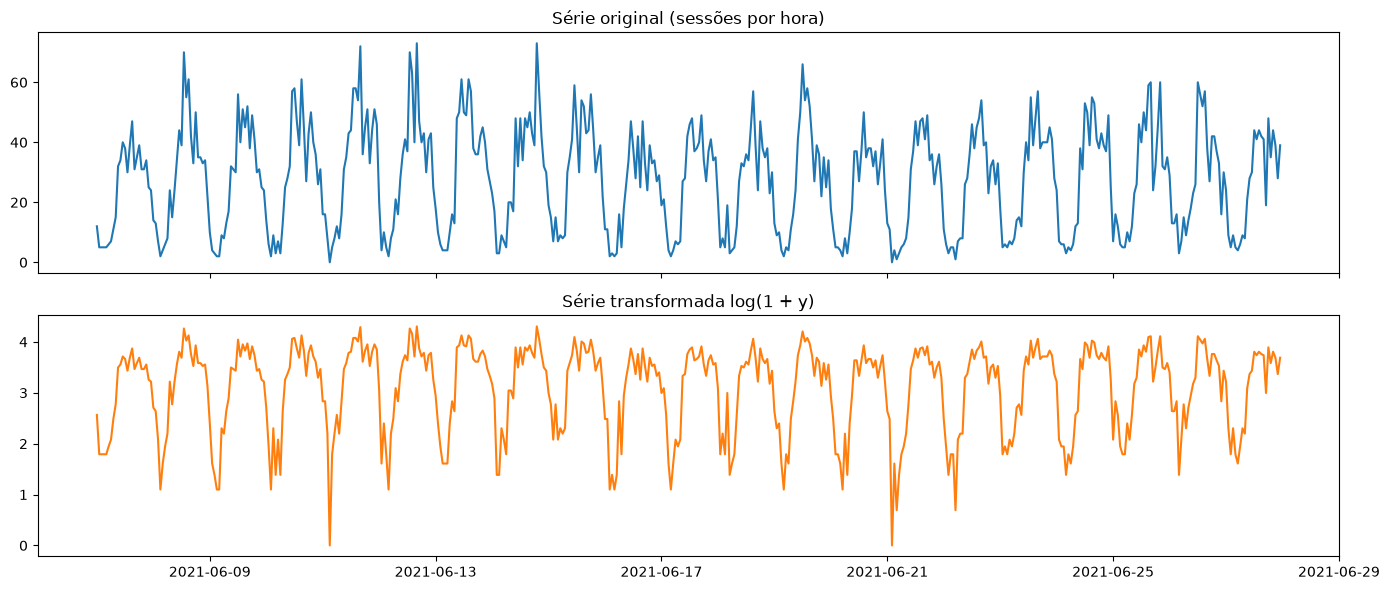

Original (y)               0.98
Transformada log(1 + y)   -0.68
Name: Correlação nível-amplitude, dtype: float64

In [5]:
# Série da rede no treino, original e transformada
y = train['Rede']
y_log = np.log1p(y)

# Comparação visual em 3 semanas
janela = slice('2021-06-07', '2021-06-27')
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(y.loc[janela], color='tab:blue')
axes[0].set_title('Série original (sessões por hora)')
axes[1].plot(y_log.loc[janela], color='tab:orange')
axes[1].set_title('Série transformada log(1 + y)')
plt.tight_layout()
plt.show()


# Teste da H2: correlação entre o nível mensal e a amplitude do padrão diário
def amplitude_vs_nivel(serie):
    tmp = serie.to_frame('valor')
    tmp['mes'] = tmp.index.to_period('M')
    tmp['hora_dia'] = tmp.index.hour
    perfis = tmp.groupby(['mes', 'hora_dia'])['valor'].mean().unstack()
    nivel = perfis.mean(axis=1)
    amplitude = perfis.max(axis=1) - perfis.min(axis=1)
    return np.corrcoef(nivel, amplitude)[0, 1]

pd.Series({'Original (y)': amplitude_vs_nivel(y),
           'Transformada log(1 + y)': amplitude_vs_nivel(y_log)},
          name='Correlação nível-amplitude').round(2)

### 2.2 Estacionariedade e diferenciação

**Conceito: diferenciação no SARIMA(p, d, q)(P, D, Q)ₘ**
O ARIMA exige uma série **estacionária**. Para isso diferencia-se a série:
- **d** - diferenças regulares: yₜ − yₜ₋₁ (remove a tendência);
- **D** - diferenças sazonais: yₜ − yₜ₋ₘ, com *m* = 24 (remove o padrão diário).

No notebook da aula (*Air Passengers*) usou-se d = 1 e D = 1. Aqui testa-se se ambas são necessárias.

**Como escolher (slide 81: diferenciação mínima adequada):**
- A série diferenciada deve ser estacionária (teste ADF: p-value < 0,05).
- Só se acrescenta uma diferença se ela for necessária. Diferenciar a mais **aumenta** a variabilidade da série e cria uma autocorrelação negativa artificial no lag 1.

**H3:** a diferença sazonal (D = 1) é necessária, porque a sazonalidade diária é forte (força de 0,906 na Task 1).
**H4:** a diferença regular (d = 1) **não** é necessária depois de D = 1: acrescentá-la sobrediferencia a série.

In [6]:
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Comparar 3 opções de diferenciação
candidatas = {
    'log(1 + y)': y_log,
    'Δ24 (D = 1)': y_log.diff(24).dropna(),
    'Δ1 Δ24 (d = 1, D = 1)': y_log.diff(24).diff(1).dropna(),
}

linhas = []
for nome, s in candidatas.items():
    v = acf(s, nlags=24)
    linhas.append({'Série': nome,
                   'ADF p-value': adfuller(s.values, autolag='AIC')[1],
                   'Desvio padrão': s.std(),
                   'ACF lag 1': v[1],
                   'ACF lag 24': v[24]})

pd.DataFrame(linhas).set_index('Série').round(3)

,ADF p-value,Desvio padrão,ACF lag 1,ACF lag 24
Série,,,,
log(1 + y),0.0,0.861,0.817,0.856
Δ24 (D = 1),0.0,0.458,0.096,-0.466
"Δ1 Δ24 (d = 1, D = 1)",0.0,0.616,-0.482,-0.491


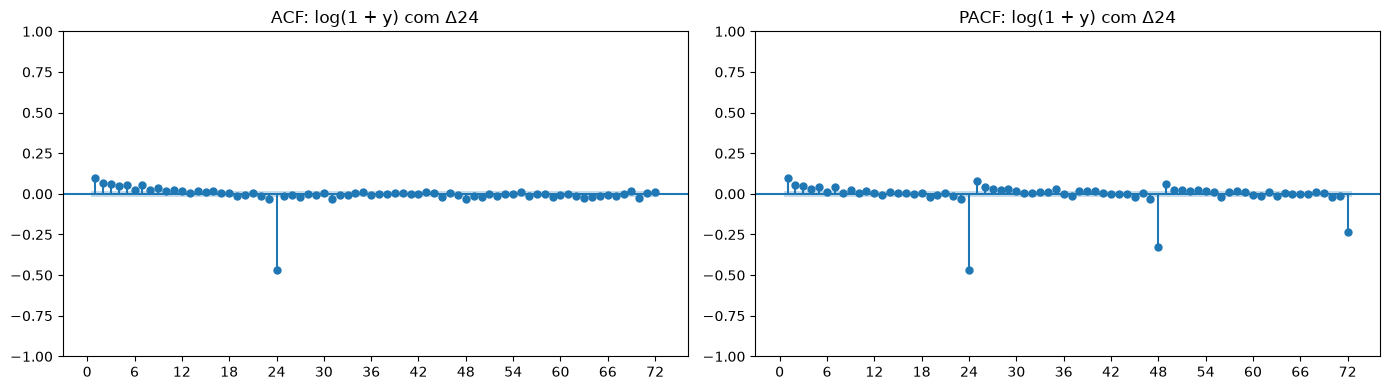

In [7]:
# ACF e PACF da série escolhida para identificar as ordens do SARIMA
y_dif = y_log.diff(24).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_dif, lags=72, zero=False, bartlett_confint=False, ax=axes[0])
plot_pacf(y_dif, lags=72, zero=False, method='ywm', ax=axes[1])
axes[0].set_title('ACF: log(1 + y) com Δ24')
axes[1].set_title('PACF: log(1 + y) com Δ24')
for ax in axes:
    ax.set_xticks(range(0, 73, 6))
plt.tight_layout()
plt.show()

**Hipóteses e validação:**

- **H2 - Depois do log, a amplitude deixa de crescer com o nível: Confirmada, com uma ressalva.**
  A correlação entre o nível mensal e a amplitude do padrão diário passa de **0,98** (original) para **-0,68** (log). A amplitude deixa de crescer com o nível, mas a relação fica negativa: a transformação **sobrecorrige** ligeiramente, porque nos meses de maior procura as horas da madrugada também sobem e, na escala log, essa subida pesa muito.
  Além disso, as horas com 0 ou 1 sessões aparecem como quedas acentuadas na escala log, o que pode gerar resíduos grandes nos modelos.
  **Decisão:** manter log(1 + y), como na aula, registando esta limitação.

- **H3 - A diferença sazonal (D = 1) é necessária: Confirmada.**
  Sem diferenciação, a ACF no lag 24 é de 0,856. Com Δ24, o desvio padrão passa de 0,861 para 0,458 e a autocorrelação de curto prazo fica perto de zero.
  O teste ADF rejeita H0 nas três opções (p ≈ 0), por isso não permite distinguir entre elas. A decisão baseia-se no desvio padrão e na ACF.

- **H4 - A diferença regular (d = 1) não é necessária: Confirmada.**
  Depois de Δ24 a série já é estacionária (ADF p ≈ 0). Acrescentar d = 1 **aumenta** o desvio padrão (0,458 → 0,616) e cria uma autocorrelação negativa forte no lag 1 (−0,482), que antes não existia (0,096). Pela regra da diferenciação mínima (slide 81), escolhe-se **d = 0 e D = 1**.
  Esta decisão é revista na secção 4, porque o melhor SARIMA tem um coeficiente AR muito perto de 1 (0,980).

**Ordens candidatas para o SARIMA (ACF/PACF de log(1 + y) com Δ24):**
- **Componente sazonal:** a ACF tem um único pico significativo no lag 24 (-0,47) e a PACF decresce nos lags 24, 48 e 72 (-0,47; -0,33; -0,24). É o padrão de uma componente **MA sazonal → Q = 1, P = 0** (tal como o lag 12 no exemplo *Air Passengers* da aula).
- **Componente não sazonal:** a ACF tem valores pequenos que decrescem lentamente e a PACF tem apenas o lag 1 significativo (~0,1), o que sugere uma componente **AR fraca → p = 1, q = 0**.

**Modelo de partida: SARIMA(1, 0, 0)(0, 1, 1)₂₄**, a comparar com candidatos semelhantes na secção 4 (critério AIC).

## 3. Suavização exponencial

### 3.1 Holt-Winters

**Conceito: suavização exponencial**
A previsão é uma média ponderada das observações passadas, com pesos que **diminuem exponencialmente** com a distância no tempo: as observações recentes pesam mais.

O **Holt-Winters** estima três componentes, cada uma com o seu parâmetro de suavização (entre 0 e 1):

| Componente | Parâmetro | Interpretação |
|---|---|---|
| Nível | α | Valor médio atual da série |
| Tendência | β (e φ se amortecida) | Crescimento por período |
| Sazonalidade | γ | Padrão que se repete a cada *m* períodos (*m* = 24) |

Um parâmetro **perto de 0** significa que a componente muda **devagar** (dá peso a muito histórico); **perto de 1** significa que se adapta **depressa** às últimas observações.

**Configuração escolhida:**
- **Sazonalidade aditiva sobre log(1 + y)** (secção 2.1). O Holt-Winters multiplicativo na escala original não pode ser usado, porque exige valores estritamente positivos e a série tem horas com 0 sessões.
- **Período sazonal *m* = 24** (sazonalidade dominante, Task 1).
- Comparam-se três opções para a tendência: **sem tendência**, **aditiva** e **amortecida**.

**Critério de escolha:** AIC (slides 81 e 86). O AIC mede o ajuste no treino penalizando a complexidade, mas não mede diretamente a capacidade de prever dados futuros. Por isso, o modelo escolhido é depois avaliado na validação (secção 6), tal como no notebook da aula.

**H5:** a componente de tendência **não melhora** o modelo, porque à escala horária a tendência é muito pequena (na Task 1, o Drift deu resultados praticamente iguais ao Naive).

In [8]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

configuracoes = {
    'Sem tendência':        dict(trend=None),
    'Tendência aditiva':    dict(trend='add', damped_trend=False),
    'Tendência amortecida': dict(trend='add', damped_trend=True),
}

modelos_hw = {}
linhas = []
for nome, cfg in configuracoes.items():
    modelo = ExponentialSmoothing(y_log, seasonal='add', seasonal_periods=24,
                                  initialization_method='estimated', **cfg).fit()
    modelos_hw[nome] = modelo
    linhas.append({'Configuração': nome,
                   'AIC': modelo.aic,
                   'α (nível)': modelo.params['smoothing_level'],
                   'β (tendência)': modelo.params['smoothing_trend'],
                   'γ (sazonalidade)': modelo.params['smoothing_seasonal'],
                   'φ (amortecimento)': modelo.params['damping_trend']})

pd.DataFrame(linhas).set_index('Configuração').round(3)

,AIC,α (nível),β (tendência),γ (sazonalidade),φ (amortecimento)
Configuração,,,,,
Sem tendência,-23719.410,0.059,NaN,0.058,NaN
Tendência aditiva,-23715.371,0.059,0.0,0.058,NaN
Tendência amortecida,-23716.561,0.059,0.0,0.058,0.8


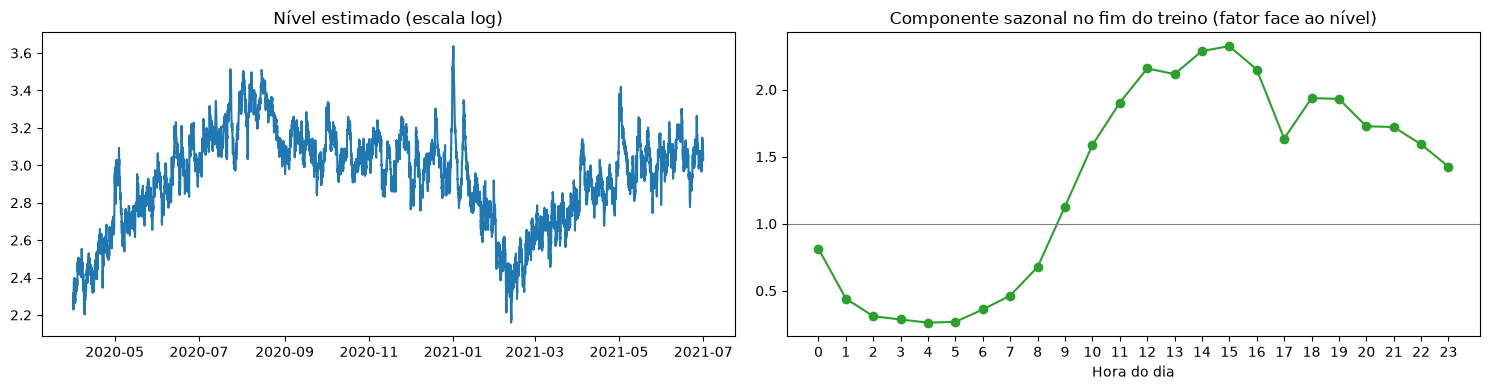

In [9]:
# Componentes do modelo escolhido (o de menor AIC)
hw = modelos_hw['Sem tendência']

# Perfil sazonal no fim do treino (últimas 24 horas), convertido com exp()
# -> fator aproximado face ao nível médio (1 = nível médio)
perfil = pd.Series(hw.season[-24:].values, index=hw.season[-24:].index.hour).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].plot(hw.level, color='tab:blue')
axes[0].set_title('Nível estimado (escala log)')

axes[1].plot(perfil.index, np.exp(perfil.values), marker='o', color='tab:green')
axes[1].axhline(1, color='gray', linewidth=0.8)
axes[1].set_title('Componente sazonal no fim do treino (fator face ao nível)')
axes[1].set_xlabel('Hora do dia')
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

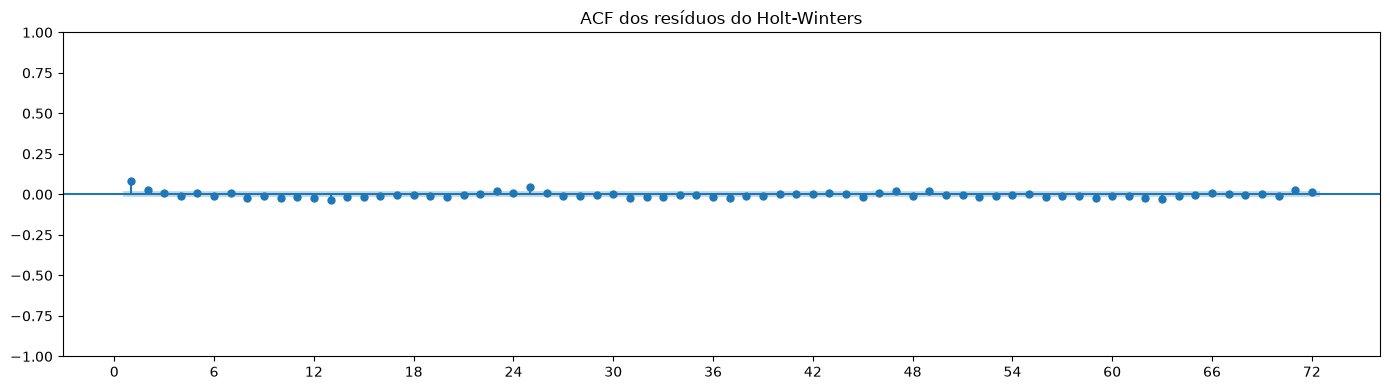

Média dos resíduos: 0.0010 | Desvio padrão: 0.338

Teste de Ljung-Box (H0: resíduos não autocorrelacionados):


,lb_stat,lb_pvalue
24,135.9408,0.0
48,195.9082,0.0


In [10]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Diagnóstico dos resíduos (as primeiras 24 horas são excluídas: período de inicialização)
residuos_hw = (y_log - hw.fittedvalues)[24:]

fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(residuos_hw, lags=72, zero=False, bartlett_confint=False, ax=ax)
ax.set_title('ACF dos resíduos do Holt-Winters')
ax.set_xticks(range(0, 73, 6))
plt.tight_layout()
plt.show()

print(f'Média dos resíduos: {residuos_hw.mean():.4f} | Desvio padrão: {residuos_hw.std():.3f}\n')
print('Teste de Ljung-Box (H0: resíduos não autocorrelacionados):')
acorr_ljungbox(residuos_hw, lags=[24, 48]).round(4)

**Hipóteses e validação:**

- **H5 - A componente de tendência não melhora o modelo: Confirmada.**
  O modelo **sem tendência** tem o menor AIC (−23 719,4). Nos modelos com tendência, o parâmetro β é estimado como **0**, ou seja, o próprio modelo anula a tendência (e o amortecimento φ = 0,8 deixa de ter efeito).
  A evolução de longo prazo é captada pelo **nível**, que se ajusta lentamente (α = 0,059): a sua evolução reproduz a tendência observada na Task 1 (subida até agosto de 2020, quebra em jan–fev de 2021 e recuperação).
  **Modelo escolhido: Holt-Winters sem tendência, com sazonalidade aditiva sobre log(1 + y) e *m* = 24.** Na notação ETS (slide 49) é um ETS(A, N, A) sobre log(1 + y).

**Componentes:**
- **Nível:** apresenta um pico isolado a 01/01/2021, que corresponde ao efeito da véspera de Ano Novo (1 219 sessões a 31/12/2020). Como o modelo não tem informação de feriados, trata este pico como uma subida do nível.
- **Sazonalidade:** muda lentamente (γ = 0,058) e reproduz o perfil diário da Task 1. Às 4h–5h a procura é cerca de **0,26 vezes** o nível médio e às 15h cerca de **2,3 vezes**, com uma quebra às 17h e um segundo pico às 18h–19h.

**Diagnóstico dos resíduos:**
- Média ≈ 0 e desvio padrão de 0,338 (escala log).
- As autocorrelações dos resíduos são **muito pequenas** (o maior valor é ~0,08 no lag 1).
- O teste de Ljung-Box rejeita H0 (p ≈ 0): os resíduos **não são ruído branco**. Com cerca de 11 mil observações, o teste deteta autocorrelações muito pequenas. Em termos práticos, a estrutura que fica por explicar é reduzida, mas existe.

**Limitações:** o Holt-Winters representa apenas **uma** sazonalidade (24h), não capta o efeito semanal nem o efeito dos feriados.

## 4. SARIMA

### 4.1 Escolha das ordens

**Conceito: SARIMA(p, d, q)(P, D, Q)ₘ**

| Parte | Parâmetros | Significado |
|---|---|---|
| Não sazonal | p, d, q | AR (lags 1…p), diferenças regulares, MA (erros 1…q) |
| Sazonal | P, D, Q, *m* | AR sazonal (lags *m*, 2*m*…), diferenças sazonais, MA sazonal |

Da secção 2: **d = 0, D = 1, *m* = 24**, e o modelo de partida é o **SARIMA(1, 0, 0)(0, 1, 1)₂₄** (ACF/PACF).
Tal como no notebook da aula, comparam-se **candidatos semelhantes** pelo **AIC** (quanto menor, melhor), variando uma ordem de cada vez:

| Candidato | O que testa |
|---|---|
| (1,0,0)(0,1,1)₂₄ | Modelo de partida |
| (0,0,1)(0,1,1)₂₄ | MA em vez de AR |
| (1,0,1)(0,1,1)₂₄ | AR + MA |
| (2,0,0)(0,1,1)₂₄ | Mais um termo AR |
| (1,0,0)(1,1,1)₂₄ | AR sazonal (P = 1) |

**Nota computacional:** com cerca de 11 mil observações horárias, cada ajuste usa muita memória. Usa-se `low_memory=True`, que reduz a memória de cerca de 3,8 GB para cerca de 0,4 GB, sem alterar os parâmetros estimados nem o AIC.

**H6:** o modelo de partida, SARIMA(1, 0, 0)(0, 1, 1)₂₄, sugerido pela ACF/PACF, tem o menor AIC entre os candidatos.

In [11]:
import time
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_candidatos = [
    {'order': (1, 0, 0), 'seasonal_order': (0, 1, 1, 24)},
    {'order': (0, 0, 1), 'seasonal_order': (0, 1, 1, 24)},
    {'order': (1, 0, 1), 'seasonal_order': (0, 1, 1, 24)},
    {'order': (2, 0, 0), 'seasonal_order': (0, 1, 1, 24)},
    {'order': (1, 0, 0), 'seasonal_order': (1, 1, 1, 24)},
]

modelos_sarima = {}
linhas = []
for cand in sarima_candidatos:
    nome = f"SARIMA{cand['order']}{cand['seasonal_order'][:3]}"
    inicio = time.time()

    modelo = SARIMAX(y_log,
                     order=cand['order'],
                     seasonal_order=cand['seasonal_order'],
                     trend='n',
                     enforce_stationarity=False,
                     enforce_invertibility=False).fit(disp=False, low_memory=True)

    modelos_sarima[nome] = modelo
    linhas.append({'Modelo': nome,
                   'AIC': modelo.aic,
                   'BIC': modelo.bic,
                   'Convergiu': modelo.mle_retvals.get('converged'),
                   'Tempo (s)': time.time() - inicio})
    print(f'{nome} ajustado')

resultados_sarima = pd.DataFrame(linhas).set_index('Modelo').sort_values('AIC').round(1)
resultados_sarima

SARIMA(1, 0, 0)(0, 1, 1) ajustado
SARIMA(0, 0, 1)(0, 1, 1) ajustado
SARIMA(1, 0, 1)(0, 1, 1) ajustado
SARIMA(2, 0, 0)(0, 1, 1) ajustado
SARIMA(1, 0, 0)(1, 1, 1) ajustado


,AIC,BIC,Convergiu,Tempo (s)
Modelo,,,,
"SARIMA(1, 0, 1)(0, 1, 1)",7255.0,7284.2,True,35.3
"SARIMA(2, 0, 0)(0, 1, 1)",7734.2,7763.4,True,20.9
"SARIMA(1, 0, 0)(0, 1, 1)",7881.2,7903.0,True,14.3
"SARIMA(1, 0, 0)(1, 1, 1)",7884.5,7913.7,True,18.0
"SARIMA(0, 0, 1)(0, 1, 1)",7955.9,7977.7,True,13.7


In [12]:
# Parâmetros estimados de cada candidato
pd.DataFrame({nome: m.params for nome, m in modelos_sarima.items()}).T.round(3)

,ar.L1,ar.L2,ar.S.L24,ma.L1,ma.S.L24,sigma2
"SARIMA(1, 0, 0)(0, 1, 1)",0.194,NaN,NaN,NaN,-0.894,0.120
"SARIMA(0, 0, 1)(0, 1, 1)",NaN,NaN,NaN,0.158,-0.887,0.121
"SARIMA(1, 0, 1)(0, 1, 1)",0.980,NaN,NaN,-0.907,-0.935,0.114
"SARIMA(2, 0, 0)(0, 1, 1)",0.176,0.118,NaN,NaN,-0.902,0.119
"SARIMA(1, 0, 0)(1, 1, 1)",0.190,NaN,0.034,NaN,-0.899,0.120


### 4.2 Diagnóstico dos resíduos

**Conceito:** se o modelo captou toda a estrutura da série, os resíduos devem ser **ruído branco**: média ≈ 0, sem autocorrelação e com variância constante. Verifica-se com:
- o **gráfico de diagnóstico** do notebook da aula (`plot_diagnostics`): resíduos ao longo do tempo, histograma, **Q-Q plot** (slides 89 e 90) e ACF;
- a **ACF dos resíduos** nos lags 1, 24, 48 e 168, para ver também se sobra algum efeito **semanal** (lag 168);
- o **teste de Ljung-Box** (H0: os resíduos não são autocorrelacionados, slide 91), tal como no notebook da aula.

**H7:** os resíduos do SARIMA escolhido não têm autocorrelação relevante, incluindo no lag 168 (efeito semanal).

Modelo escolhido: SARIMA(1, 0, 1)(0, 1, 1) 



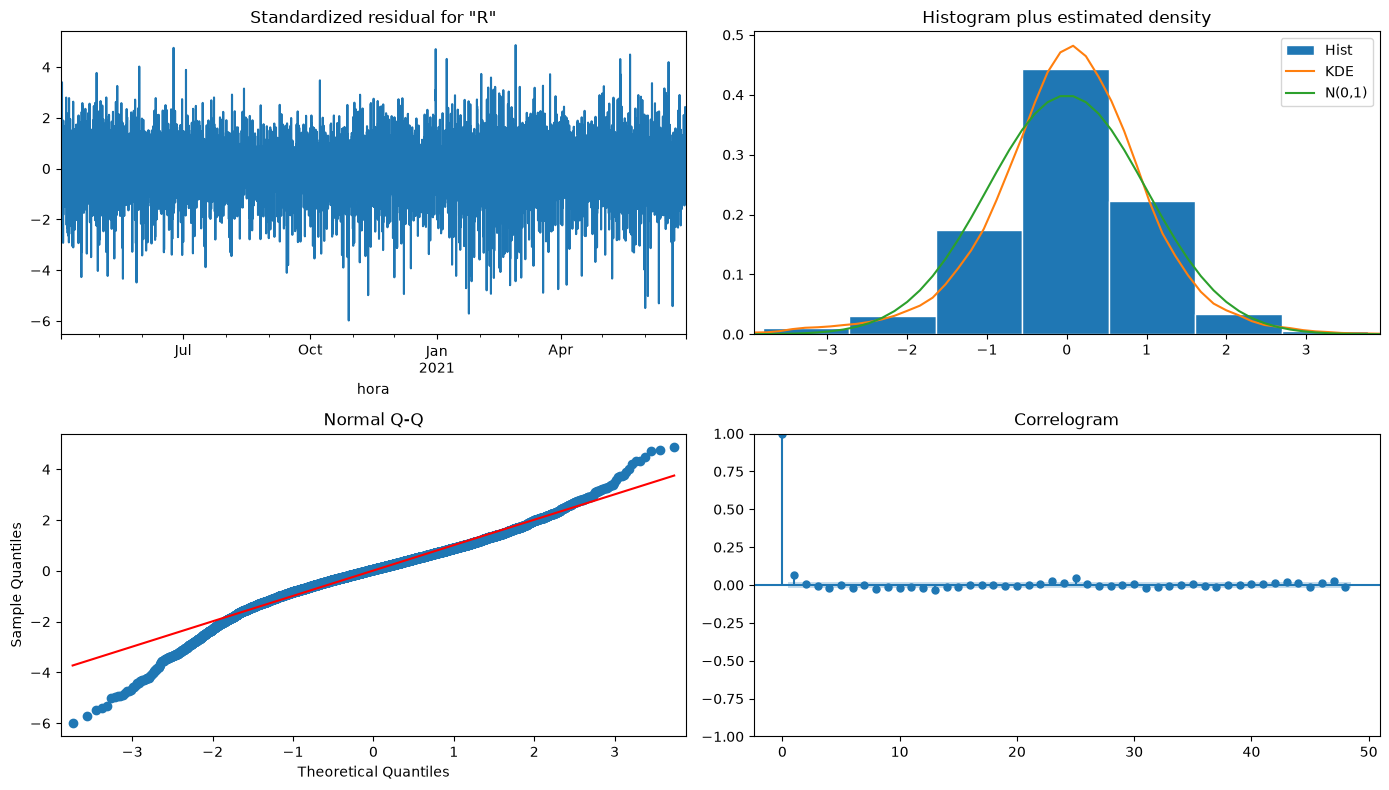

Média: 0.0045 | Desvio padrão: 0.338
ACF dos resíduos em lags-chave: {1: np.float64(0.062), 24: np.float64(0.012), 48: np.float64(-0.011), 168: np.float64(0.016)} 

Teste de Ljung-Box (H0: resíduos não autocorrelacionados):


,lb_stat,lb_pvalue
24,94.3340,0.0
48,150.0706,0.0
168,311.4073,0.0


In [13]:
# Modelo com menor AIC
melhor_sarima = resultados_sarima.index[0]
sarima = modelos_sarima[melhor_sarima]
print('Modelo escolhido:', melhor_sarima, '\n')

# Resíduos sem o período de inicialização (como no notebook da aula)
residuos_sarima = sarima.resid.iloc[sarima.loglikelihood_burn:]

# Diagnóstico da aula: resíduos, histograma, Q-Q plot e ACF
sarima.plot_diagnostics(lags=48, figsize=(14, 8))
plt.tight_layout()
plt.show()

v = acf(residuos_sarima, nlags=192)
print(f'Média: {residuos_sarima.mean():.4f} | Desvio padrão: {residuos_sarima.std():.3f}')
print('ACF dos resíduos em lags-chave:', {lag: round(v[lag], 3) for lag in [1, 24, 48, 168]}, '\n')

print('Teste de Ljung-Box (H0: resíduos não autocorrelacionados):')
acorr_ljungbox(residuos_sarima, lags=[24, 48, 168]).round(4)

**Hipóteses e validação:**

- **H6 - O modelo de partida SARIMA(1,0,0)(0,1,1)₂₄ tem o menor AIC: Rejeitada.**
  O melhor modelo é o **SARIMA(1,0,1)(0,1,1)₂₄** (AIC = 7 255,0), cerca de 626 pontos abaixo do modelo de partida (7 881,2). A ACF/PACF deu um bom ponto de partida, mas a comparação de candidatos pelo AIC encontrou uma especificação melhor, tal como no notebook da aula. Todos os modelos convergiram.
  - **ar.L1 = 0,980 e ma.L1 = −0,907:** o coeficiente AR está muito perto de 1, o limite da condição de estacionariedade (slide 60). Isto indica que o nível da série muda lentamente e se comporta quase como um passeio aleatório, ou seja, a série está perto de precisar de d = 1. O MA negativo forte compensa esse efeito.
  - **ma.S.L24 ≈ −0,9** em todos os candidatos: a componente MA sazonal (Q = 1) é confirmada.
  - **ar.S.L24 = 0,034** e AIC pior do que sem esse termo: confirma-se P = 0.
  - O melhor modelo é também o mais lento a ajustar (~35 s, contra 14–23 s dos restantes).

- **H7 - Os resíduos não têm autocorrelação relevante: Parcialmente confirmada.**
  - As autocorrelações dos resíduos são **muito pequenas** (lag 1: 0,062; lag 24: 0,012; lag 168: 0,016). Em particular, **não sobra efeito semanal** relevante.
  - A variância dos resíduos é aproximadamente constante ao longo do tempo, e a média é ≈ 0 (desvio padrão de 0,338).
  - O teste de Ljung-Box rejeita H0 (p ≈ 0): com cerca de 11 mil observações, o teste deteta autocorrelações muito pequenas. Em termos práticos, a estrutura por explicar é reduzida. A análise de resíduos é um diagnóstico da adequação do modelo e não uma condição obrigatória para prever (slide 88).
  - O histograma está centrado em 0. No Q-Q plot, os pontos seguem a reta na zona central, mas a **cauda esquerda afasta-se** para baixo: há mais resíduos negativos grandes do que numa distribuição normal. Correspondem às horas com 0 ou 1 sessões, que na escala log aparecem como quedas acentuadas (secção 2.1). A normalidade não é obrigatória para prever (slide 90).

**Modelo escolhido: SARIMA(1,0,1)(0,1,1)₂₄ sobre log(1 + y).**

### 4.3 Resumo das decisões

| Tema | Decisão | Secção |
|---|---|---|
| Transformação | log(1 + y); previsões convertidas com `np.expm1` | 2.1 |
| Diferenciação | d = 0, D = 1, *m* = 24 | 2.2 |
| Holt-Winters | Sem tendência, sazonalidade aditiva, *m* = 24 (α = 0,059; γ = 0,058) | 3 |
| SARIMA | (1,0,1)(0,1,1)₂₄, `trend='n'`, `enforce_stationarity=False`, `enforce_invertibility=False` | 4.1 |
| Efeito semanal | Não sobra autocorrelação relevante no lag 168 (0,016). O ganho do SARIMAX com o dia da semana deve ser **testado** | 4.2 |
| Séries | Configurações escolhidas com a **rede**; aplicar as mesmas às 4 séries na avaliação | — |
| SARIMA da aula | (0,1,1)(0,1,1)₂₄ também é avaliado na validação, porque ar.L1 = 0,98 está perto de 1. Não se compara pelo AIC com o (1,0,1)(0,1,1)₂₄, porque a diferenciação é diferente (slide 81: comparar o AIC só entre modelos ajustados aos mesmos dados) | 4.1 |

**Nota para a avaliação (secção 6):**
- O AIC do Holt-Winters e o do SARIMA **não são comparáveis** entre si (são calculados de formas diferentes). A comparação entre modelos faz-se na **validação**, com MAE, RMSE e MASE.

## 5. SARIMAX

### 5.1 Variáveis de calendário

**Conceito: SARIMAX (slides 95 e 96)**
O SARIMAX acrescenta ao SARIMA variáveis exógenas (X). Pode ser visto como uma **regressão cujos erros seguem um SARIMA**: yₜ = β₀ + β₁x₁,ₜ + … + nₜ, com nₜ ~ SARIMA(p, d, q)(P, D, Q)ₘ.
O modelo precisa dos **valores futuros** das variáveis exógenas, por isso só se podem usar variáveis conhecidas no momento da previsão (slide 96).

**Variáveis escolhidas: dia da semana**
- O SARIMA só representa uma sazonalidade (*m* = 24). A sazonalidade semanal (*m* = 168) é fraca, mas não nula (Task 1, H13), e um SARIMA com *m* = 168 seria muito exigente em termos computacionais com dados horários.
- O dia da semana é **futuro conhecido** (Task 1, secção 3.3): às 23:00 já se sabe que dia é o dia seguinte, por isso não há *leakage*.
- Usam-se **6 variáveis dummy** (terça a domingo), com a segunda-feira como referência. A variável fim de semana não é usada, porque repetiria a informação dos dias (multicolinearidade, slide 96).
- A meteorologia continua excluída (Task 1, secção 3.3).
- Mantêm-se as ordens do SARIMA escolhido, (1,0,1)(0,1,1)₂₄. Como os dois modelos usam os mesmos dados e a mesma diferenciação, o **AIC é comparável**.

**H8:** acrescentar o dia da semana melhora o SARIMA (AIC mais baixo), mas o ganho é pequeno, porque a sazonalidade semanal é fraca.

In [14]:
# Variáveis de calendário: dia da semana (segunda-feira = referência)
def calendario(indice):
    dias = pd.get_dummies(indice.dayofweek, prefix='dia', drop_first=True).astype(float)
    dias.index = indice
    return dias

X_train = calendario(y_log.index)
print('Variáveis exógenas:', X_train.columns.tolist())

inicio = time.time()
sarimax = SARIMAX(y_log, exog=X_train,
                  order=(1, 0, 1),
                  seasonal_order=(0, 1, 1, 24),
                  trend='n',
                  enforce_stationarity=False,
                  enforce_invertibility=False).fit(disp=False, low_memory=True)
print(f'Tempo de ajuste: {time.time() - inicio:.1f} s\n')

pd.DataFrame({'AIC': [sarima.aic, sarimax.aic],
              'BIC': [sarima.bic, sarimax.bic]},
             index=['SARIMA(1,0,1)(0,1,1)24',
                    'SARIMAX(1,0,1)(0,1,1)24 + dia da semana']).round(1)

Variáveis exógenas: ['dia_1', 'dia_2', 'dia_3', 'dia_4', 'dia_5', 'dia_6']
Tempo de ajuste: 306.1 s



,AIC,BIC
"SARIMA(1,0,1)(0,1,1)24",7255.0,7284.2
"SARIMAX(1,0,1)(0,1,1)24 + dia da semana",7240.3,7313.3


In [15]:
# Coeficientes estimados (escala log) e respetivos p-values
pd.DataFrame({'Coeficiente': sarimax.params, 'p-value': sarimax.pvalues}).round(3)

,Coeficiente,p-value
dia_1,-0.026,0.093
dia_2,-0.022,0.238
dia_3,0.017,0.395
dia_4,0.049,0.012
dia_5,0.066,0.000
dia_6,0.038,0.012
ar.L1,0.982,0.000
ma.L1,-0.915,0.000
ma.S.L24,-0.935,0.000
sigma2,0.113,0.000


**Hipóteses e validação:**

- **H8 - O dia da semana melhora o SARIMA, mas o ganho é pequeno: Confirmada.**
  - O AIC desce de 7 255,0 para **7 240,3** (−14,7), uma melhoria pequena face às diferenças entre os candidatos SARIMA (secção 4.1, até 626 pontos). O BIC, que penaliza mais os parâmetros, **sobe** (7 284,2 → 7 313,3).
  - Os coeficientes estão na escala log e são relativos à segunda-feira. Só sexta (+0,049), sábado (+0,066) e domingo (+0,038) são significativos (p < 0,05), o que corresponde a cerca de **4% a 7% mais sessões**. Terça, quarta e quinta não são diferentes da segunda-feira (p > 0,05). Isto confirma que o efeito semanal existe, mas é fraco (Task 1, H13).
  - Os parâmetros do SARIMA praticamente não mudam (ar.L1 = 0,982; ma.L1 = −0,915; ma.S.L24 = −0,935).
  - **Custo computacional:** o ajuste demora cerca de **306 s**, contra cerca de 35 s do SARIMA, ou seja, cerca de 9 vezes mais.

**Decisão:** o SARIMAX é mantido como candidato e a escolha entre SARIMA e SARIMAX é feita na **validação** (secção 6), porque o AIC e o BIC não estão de acordo e o slide 97 indica que, no SARIMAX, a escolha deve combinar a avaliação dos preditores com a validação temporal.

## 6. Avaliação na validação

### 6.1 Previsões nas 92 origens

**Como são geradas as previsões (protocolo da Task 1, secção 4.1):**
- Para cada série (rede e 3 distritos), os parâmetros de cada modelo são estimados **uma vez**, no treino, com as configurações escolhidas nas secções 3 a 5.
- Em cada origem (23:00 de cada dia, de 30/06 a 29/09/2021) são previstas as 24 horas do dia seguinte, usando apenas valores observados até à origem. Os parâmetros **não são reestimados**.
- **Holt-Winters:** o modelo é aplicado aos dados até à origem com os parâmetros fixos (`optimized=False`) e depois usa-se `.forecast(24)`, como no notebook da aula.
- **SARIMA e SARIMAX:** com `.filter()`, os parâmetros do treino são aplicados a todo o período, sem reestimar. Depois, `get_prediction(..., dynamic=True)` prevê as 24 horas a partir de cada origem. A partir da primeira hora prevista, o modelo deixa de usar os valores observados e passa a usar as suas próprias previsões (estratégia recursiva).
- As previsões são convertidas para a escala original com `np.expm1`.

**Modelos avaliados:** Holt-Winters, SARIMA(1,0,1)(0,1,1)₂₄, SARIMA da aula (0,1,1)(0,1,1)₂₄ e SARIMAX(1,0,1)(0,1,1)₂₄ com o dia da semana.

In [16]:
# Origens: todos os dias às 23:00, de 30/06/2021 a 29/09/2021 (92 origens)
origens = pd.date_range(f'{TRAIN_END} 23:00', periods=92, freq='D')

periodo = series.loc[TRAIN_START:VALIDATION_END]    # valores observados (treino + validação)
X_tr = calendario(train.index)
X_per = calendario(periodo.index)

configs_sarima = {
    'SARIMA(1,0,1)(0,1,1)24':       {'order': (1, 0, 1), 'exog': False},
    'SARIMA aula (0,1,1)(0,1,1)24': {'order': (0, 1, 1), 'exog': False},
    'SARIMAX(1,0,1)(0,1,1)24':      {'order': (1, 0, 1), 'exog': True},
}

previsoes = {}    # (série, modelo) -> previsões das 2208 horas da validação
tempos = []

for c in series.columns:
    y_tr = np.log1p(train[c])
    y_per = np.log1p(periodo[c])

    # --- Holt-Winters ---
    inicio = time.time()
    hw_c = ExponentialSmoothing(y_tr, seasonal='add', seasonal_periods=24,
                                initialization_method='estimated').fit()
    tempos.append({'Série': c, 'Modelo': 'Holt-Winters', 'Tempo (s)': time.time() - inicio})

    prev = []
    for o in origens:
        modelo_o = ExponentialSmoothing(y_per.loc[:o], seasonal='add', seasonal_periods=24,
                                        initialization_method='known',
                                        initial_level=hw_c.params['initial_level'],
                                        initial_seasonal=hw_c.params['initial_seasons'])
        ajuste_o = modelo_o.fit(smoothing_level=hw_c.params['smoothing_level'],
                                smoothing_seasonal=hw_c.params['smoothing_seasonal'],
                                optimized=False)
        prev.append(ajuste_o.forecast(24))
    previsoes[(c, 'Holt-Winters')] = np.expm1(pd.concat(prev))

    # --- SARIMA e SARIMAX ---
    for nome, cfg in configs_sarima.items():
        ex_tr = X_tr if cfg['exog'] else None
        ex_per = X_per if cfg['exog'] else None

        inicio = time.time()
        ajuste = SARIMAX(y_tr, exog=ex_tr, order=cfg['order'], seasonal_order=(0, 1, 1, 24),
                         trend='n', enforce_stationarity=False,
                         enforce_invertibility=False).fit(disp=False, low_memory=True)
        tempos.append({'Série': c, 'Modelo': nome, 'Tempo (s)': time.time() - inicio})

        # Aplicar os parâmetros do treino a todo o período (sem reestimar)
        filtro = SARIMAX(y_per, exog=ex_per, order=cfg['order'], seasonal_order=(0, 1, 1, 24),
                         trend='n', enforce_stationarity=False,
                         enforce_invertibility=False).filter(ajuste.params)

        prev = []
        for o in origens:
            p = filtro.get_prediction(start=o + pd.Timedelta(hours=1),
                                      end=o + pd.Timedelta(hours=24), dynamic=True)
            prev.append(p.predicted_mean)
        previsoes[(c, nome)] = np.expm1(pd.concat(prev))
        del filtro    # liberta memória

    print(c, 'concluída')

tempos = pd.DataFrame(tempos)
tempos.pivot(index='Modelo', columns='Série', values='Tempo (s)').round(1)

Rede concluída
Nanhu concluída
Tongxiang concluída
Xiuzhou concluída


Série,Nanhu,Rede,Tongxiang,Xiuzhou
Modelo,,,,
Holt-Winters,0.4,0.4,0.3,0.3
"SARIMA aula (0,1,1)(0,1,1)24",18.9,16.1,15.0,21.4
"SARIMA(1,0,1)(0,1,1)24",43.9,31.6,30.5,35.5
"SARIMAX(1,0,1)(0,1,1)24",266.3,303.4,313.1,349.9


### 6.2 Comparação com o Seasonal Naive

Cada modelo é comparado com o Seasonal Naive (*m* = 24), a baseline de referência da Task 1, com MAE, RMSE e MASE. A escala do MASE é calculada no treino de cada série (Task 1, secção 4.2), por isso o MASE permite comparar a rede com os distritos.

**H9:** os modelos estatísticos têm um MASE inferior ao do Seasonal Naive nas 4 séries.
**H10:** o SARIMAX (com o dia da semana) tem um erro inferior ao SARIMA(1,0,1)(0,1,1)₂₄, mas a diferença é pequena (secção 5, H8).

In [17]:
# Métricas na validação: Seasonal Naive + 4 modelos, para as 4 séries
modelos = ['Holt-Winters'] + list(configs_sarima)

linhas = []
for c in series.columns:
    linha = {'Série': c, 'Modelo': 'Seasonal Naive'}
    linha.update(forecast_metrics(validation[c], sn_val[c], train[c]))
    linhas.append(linha)
    for m in modelos:
        linha = {'Série': c, 'Modelo': m}
        linha.update(forecast_metrics(validation[c], previsoes[(c, m)], train[c]))
        linhas.append(linha)

resultados_val = pd.DataFrame(linhas)
resultados_val.set_index(['Série', 'Modelo']).round(3)

MAE    RMSE   MASE
Série     Modelo                                            
Rede      Seasonal Naive                8.196  11.166  1.187
          Holt-Winters                  6.146   8.456  0.890
          SARIMA(1,0,1)(0,1,1)24        6.170   8.521  0.893
          SARIMA aula (0,1,1)(0,1,1)24  6.178   8.487  0.894
          SARIMAX(1,0,1)(0,1,1)24       6.200   8.566  0.898
Nanhu     Seasonal Naive                2.485   3.529  0.979
          Holt-Winters                  1.941   2.787  0.765
          SARIMA(1,0,1)(0,1,1)24        1.967   2.860  0.775
          SARIMA aula (0,1,1)(0,1,1)24  1.941   2.773  0.765
          SARIMAX(1,0,1)(0,1,1)24       2.001   2.919  0.789
Tongxiang Seasonal Naive                5.058   7.126  1.159
          Holt-Winters                  3.717   5.159  0.852
          SARIMA(1,0,1)(0,1,1)24        3.729   5.191  0.855
          SARIMA aula (0,1,1)(0,1,1)24  3.723   5.164  0.853
          SARIMAX(1,0,1)(0,1,1)24       3.740   5.195  0.857
Xiuzhou   Seasonal Naive                5.316   7.196  1.342
          Holt-Winters                  4.003   5.516  1.010
          SARIMA(1,0,1)(0,1,1)24        4.011   5.568  1.012
          SARIMA aula (0,1,1)(0,1,1)24  4.011   5.514  1.012
          SARIMAX(1,0,1)(0,1,1)24       4.022   5.599  1.015

In [18]:
# MASE na validação (comparar cada modelo com a linha do Seasonal Naive)
resultados_val.pivot(index='Modelo', columns='Série', values='MASE').round(3)

Série,Nanhu,Rede,Tongxiang,Xiuzhou
Modelo,,,,
Holt-Winters,0.765,0.890,0.852,1.010
"SARIMA aula (0,1,1)(0,1,1)24",0.765,0.894,0.853,1.012
"SARIMA(1,0,1)(0,1,1)24",0.775,0.893,0.855,1.012
"SARIMAX(1,0,1)(0,1,1)24",0.789,0.898,0.857,1.015
Seasonal Naive,0.979,1.187,1.159,1.342


**Hipóteses e validação:**

- **H9 - Os modelos estatísticos têm um MASE inferior ao do Seasonal Naive nas 4 séries: Confirmada.**
  Todos os modelos reduzem o MASE em cerca de **22% a 26%** face ao Seasonal Naive (por exemplo, na rede: 1,187 → 0,890 com o Holt-Winters; em Tongxiang: 1,159 → 0,852).
  Em Xiuzhou o MASE fica perto de 1 (1,010), mas isto não significa que o modelo seja igual à baseline: a escala do MASE é o erro do Seasonal Naive **no treino**. Na validação, o Seasonal Naive de Xiuzhou tem um MASE de 1,342, por isso a melhoria também existe nesta série.
  A série mais fácil de prever, em termos relativos, é Nanhu (0,765) e a mais difícil é Xiuzhou (1,010).

- **H10 - O SARIMAX tem um erro inferior ao SARIMA: Rejeitada.**
  Nas 4 séries, o SARIMAX tem um MASE ligeiramente **pior** do que o SARIMA(1,0,1)(0,1,1)₂₄ (rede: 0,898 contra 0,893). A pequena melhoria do AIC no treino (H8) não se traduz numa melhoria na validação. Como a sazonalidade semanal é fraca, o dia da semana não acrescenta informação útil e o modelo fica cerca de 9 vezes mais lento.

**Comparação entre os modelos:**
- As diferenças entre os 4 modelos são muito pequenas (no máximo 0,024 de MASE, em Nanhu).
- O **Holt-Winters** tem o menor MASE em todas as séries (empatado com o SARIMA da aula em Nanhu) e é, de longe, o mais rápido (menos de 1 s, contra 15 a 45 s dos SARIMA e cerca de 5 minutos do SARIMAX).
- O **SARIMA da aula, (0,1,1)(0,1,1)₂₄**, é igual ou melhor do que o SARIMA(1,0,1)(0,1,1)₂₄ em 3 das 4 séries e ajusta-se em cerca de metade do tempo. Isto confirma o que se viu na secção 4: o coeficiente AR de 0,98 estava a aproximar uma diferença regular.

### 6.3 Erros por horizonte e por mês

Como a origem é sempre às 23:00, o horizonte *h* corresponde à hora prevista: *h* = 1 → 00:00, …, *h* = 24 → 23:00. O MASE é calculado separadamente para cada horizonte (como na Task 1, secção 4.3) e para cada mês da validação (julho, agosto e setembro).

**H11:** o erro dos modelos estatísticos aumenta com o horizonte, porque a estratégia recursiva acumula erros (Task 1, secção 3.2).
**H12:** os modelos estatísticos ganham ao Seasonal Naive nos 3 meses da validação (desempenho estável no tempo).

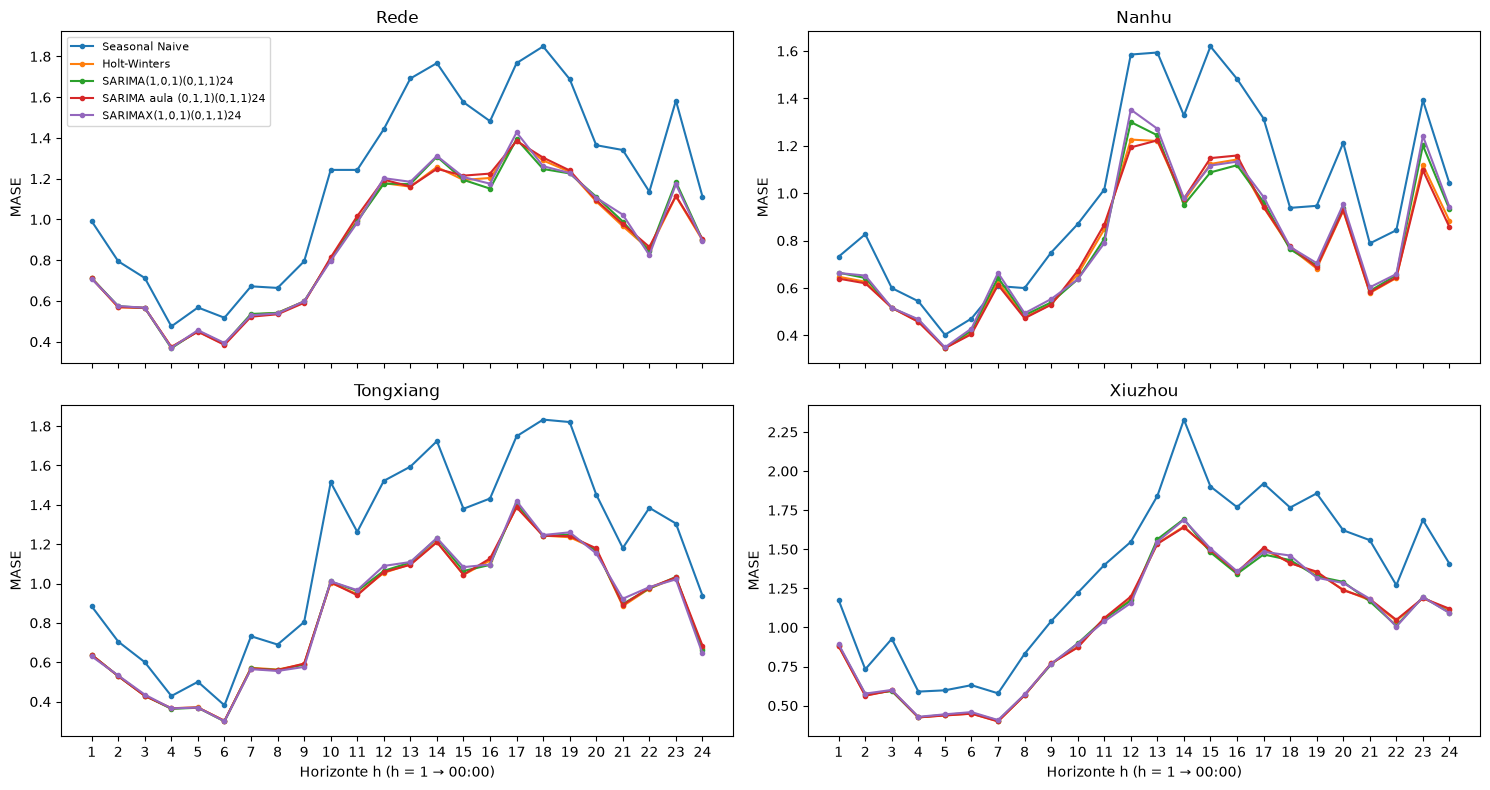

In [19]:
# Escala do MASE de cada série: MAE do Seasonal Naive (m = 24) no treino
escala = {c: np.mean(np.abs(train[c].values[24:] - train[c].values[:-24])) for c in series.columns}
modelos_todos = ['Seasonal Naive'] + modelos

def erro_escalado(c, m):
    prev = sn_val[c] if m == 'Seasonal Naive' else previsoes[(c, m)]
    return (validation[c] - prev).abs() / escala[c]    # a média destes valores é o MASE

horizonte = validation.index.hour + 1

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for ax, c in zip(axes.flat, series.columns):
    for m in modelos_todos:
        ax.plot(range(1, 25), erro_escalado(c, m).groupby(horizonte).mean(), marker='o', markersize=3, label=m)
    ax.set_title(c)
    ax.set_xticks(range(1, 25))
    ax.set_ylabel('MASE')
axes[1, 0].set_xlabel('Horizonte h (h = 1 → 00:00)')
axes[1, 1].set_xlabel('Horizonte h (h = 1 → 00:00)')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [20]:
# MASE por mês da validação
mes = validation.index.month

linhas = []
for c in series.columns:
    for m in modelos_todos:
        por_mes = erro_escalado(c, m).groupby(mes).mean()
        linhas.append({'Série': c, 'Modelo': m,
                       'Julho': por_mes[7], 'Agosto': por_mes[8], 'Setembro': por_mes[9]})

pd.DataFrame(linhas).set_index(['Série', 'Modelo']).round(3)

Julho  Agosto  Setembro
Série     Modelo                                               
Rede      Seasonal Naive                1.154   1.200     1.206
          Holt-Winters                  0.839   0.887     0.946
          SARIMA(1,0,1)(0,1,1)24        0.859   0.883     0.939
          SARIMA aula (0,1,1)(0,1,1)24  0.841   0.889     0.956
          SARIMAX(1,0,1)(0,1,1)24       0.864   0.885     0.946
Nanhu     Seasonal Naive                0.881   0.845     1.220
          Holt-Winters                  0.655   0.624     1.025
          SARIMA(1,0,1)(0,1,1)24        0.659   0.626     1.048
          SARIMA aula (0,1,1)(0,1,1)24  0.654   0.625     1.024
          SARIMAX(1,0,1)(0,1,1)24       0.667   0.631     1.078
Tongxiang Seasonal Naive                1.184   1.181     1.110
          Holt-Winters                  0.851   0.858     0.846
          SARIMA(1,0,1)(0,1,1)24        0.865   0.855     0.844
          SARIMA aula (0,1,1)(0,1,1)24  0.851   0.861     0.847
          SARIMAX(1,0,1)(0,1,1)24       0.873   0.858     0.839
Xiuzhou   Seasonal Naive                1.332   1.311     1.382
          Holt-Winters                  0.983   0.984     1.066
          SARIMA(1,0,1)(0,1,1)24        0.988   0.979     1.072
          SARIMA aula (0,1,1)(0,1,1)24  0.983   0.986     1.070
          SARIMAX(1,0,1)(0,1,1)24       0.991   0.980     1.077

**Hipóteses e validação:**

- **H11 - O erro aumenta com o horizonte: Rejeitada.**
  O erro não cresce de *h* = 1 para *h* = 24: acompanha o **padrão diário da procura**. Como a origem é sempre às 23:00, cada horizonte corresponde a uma hora do dia. O MASE é mais baixo de madrugada (*h* = 4 a 7, ou seja, 03:00 a 06:00, cerca de 0,4 na rede), quando há poucas sessões, e mais alto à tarde (*h* = 12 a 19), quando a procura é maior e mais variável. Em todas as séries há também um pico isolado em *h* = 23 (22:00), que aparece igualmente no Seasonal Naive.
  Os modelos estatísticos ficam abaixo do Seasonal Naive em praticamente todos os horizontes, e a diferença é maior nas horas de maior procura (por exemplo, na rede às 17:00 (*h* = 18): 1,85 contra cerca de 1,27). A única exceção é Nanhu às 06:00 (*h* = 7), onde os erros são praticamente iguais.
  Os 4 modelos têm curvas quase sobrepostas: nenhum se destaca num horizonte específico.

- **H12 - Os modelos ganham ao Seasonal Naive nos 3 meses da validação: Confirmada.**
  Em todas as séries e em todos os meses, o MASE dos modelos é inferior ao do Seasonal Naive (por exemplo, rede com o Holt-Winters: 0,839 / 0,887 / 0,946 contra 1,154 / 1,200 / 1,206).
  O erro sobe ligeiramente ao longo da validação na rede, em Nanhu e em Xiuzhou, mas o Seasonal Naive também sobe, por isso a vantagem dos modelos mantém-se.
  Setembro é o mês mais difícil em Nanhu (Holt-Winters: 1,025, contra cerca de 0,64 em julho e agosto), também para o Seasonal Naive (1,220). Isto pode estar relacionado com as interrupções em locais de Nanhu identificadas na Task 1.
  O melhor modelo muda de mês para mês, mas as diferenças entre modelos são sempre pequenas (no máximo 0,05).

**Decisão (modelo para o teste):**
- **Holt-Winters:** tem o menor MASE global em todas as séries (secção 6.2), um desempenho estável por horizonte e por mês, e é de longe o mais rápido. É o modelo estatístico escolhido.
- Tal como no notebook da aula, o teste inclui também o melhor SARIMA: o **SARIMA da aula (0,1,1)(0,1,1)₂₄**, que é igual ou melhor do que o (1,0,1)(0,1,1)₂₄ em 3 das 4 séries e mais rápido.
- O SARIMAX não passa ao teste (H10).

## 7. Modelo final

### 7.1 Avaliação no teste

Tal como no notebook da aula e no protocolo da Task 1 (secção 4.1), os modelos escolhidos são **treinados de novo com treino + validação** (`development`, de 01/04/2020 a 30/09/2021) e avaliados **uma única vez** no teste (01/10 a 31/12/2021), com 92 origens às 23:00. A escala do MASE é calculada em `development` (Task 1, secção 4.2).

Modelos: Seasonal Naive (baseline), Holt-Winters e SARIMA(0,1,1)(0,1,1)₂₄.

**Nota:** o teste inclui as interrupções em Nanhu (Technology Park sem sessões desde 29/09/2021; Tourist Attraction de 14 a 27/12/2021, Task 1 secção 1.3).

**H13:** o Holt-Winters continua a ganhar ao Seasonal Naive no teste, nas 4 séries.

In [21]:
origens_teste = pd.date_range(f'{VALIDATION_END} 23:00', periods=92, freq='D')
periodo_teste = series.loc[TRAIN_START:TEST_END]
sn_teste = series.shift(24).loc[TEST_START:TEST_END]
nome_sarima = 'SARIMA aula (0,1,1)(0,1,1)24'

previsoes_teste = {}

for c in series.columns:
    y_dev = np.log1p(development[c])
    y_all = np.log1p(periodo_teste[c])

    # --- Holt-Winters ---
    hw_c = ExponentialSmoothing(y_dev, seasonal='add', seasonal_periods=24,
                                initialization_method='estimated').fit()
    prev = []
    for o in origens_teste:
        modelo_o = ExponentialSmoothing(y_all.loc[:o], seasonal='add', seasonal_periods=24,
                                        initialization_method='known',
                                        initial_level=hw_c.params['initial_level'],
                                        initial_seasonal=hw_c.params['initial_seasons'])
        ajuste_o = modelo_o.fit(smoothing_level=hw_c.params['smoothing_level'],
                                smoothing_seasonal=hw_c.params['smoothing_seasonal'],
                                optimized=False)
        prev.append(ajuste_o.forecast(24))
    previsoes_teste[(c, 'Holt-Winters')] = np.expm1(pd.concat(prev))

    # --- SARIMA da aula ---
    ajuste = SARIMAX(y_dev, order=(0, 1, 1), seasonal_order=(0, 1, 1, 24),
                     trend='n', enforce_stationarity=False,
                     enforce_invertibility=False).fit(disp=False, low_memory=True)
    filtro = SARIMAX(y_all, order=(0, 1, 1), seasonal_order=(0, 1, 1, 24),
                     trend='n', enforce_stationarity=False,
                     enforce_invertibility=False).filter(ajuste.params)
    prev = []
    for o in origens_teste:
        p = filtro.get_prediction(start=o + pd.Timedelta(hours=1),
                                  end=o + pd.Timedelta(hours=24), dynamic=True)
        prev.append(p.predicted_mean)
    previsoes_teste[(c, nome_sarima)] = np.expm1(pd.concat(prev))
    del filtro

    print(c, 'concluída')

# Métricas no teste (escala do MASE: treino + validação)
linhas = []
for c in series.columns:
    for m, prev in [('Seasonal Naive', sn_teste[c]),
                    ('Holt-Winters', previsoes_teste[(c, 'Holt-Winters')]),
                    (nome_sarima, previsoes_teste[(c, nome_sarima)])]:
        linha = {'Série': c, 'Modelo': m}
        linha.update(forecast_metrics(test[c], prev, development[c]))
        linhas.append(linha)

resultados_teste = pd.DataFrame(linhas)
resultados_teste.set_index(['Série', 'Modelo']).round(3)

Rede concluída
Nanhu concluída
Tongxiang concluída
Xiuzhou concluída


MAE    RMSE   MASE
Série     Modelo                                            
Rede      Seasonal Naive                7.934  10.447  1.114
          Holt-Winters                  6.078   8.029  0.853
          SARIMA aula (0,1,1)(0,1,1)24  6.107   8.064  0.857
Nanhu     Seasonal Naive                2.587   3.722  1.023
          Holt-Winters                  2.117   2.989  0.837
          SARIMA aula (0,1,1)(0,1,1)24  2.125   3.012  0.840
Tongxiang Seasonal Naive                4.884   6.401  1.090
          Holt-Winters                  3.601   4.717  0.804
          SARIMA aula (0,1,1)(0,1,1)24  3.609   4.728  0.805
Xiuzhou   Seasonal Naive                5.374   7.264  1.283
          Holt-Winters                  3.964   5.408  0.946
          SARIMA aula (0,1,1)(0,1,1)24  3.981   5.432  0.950

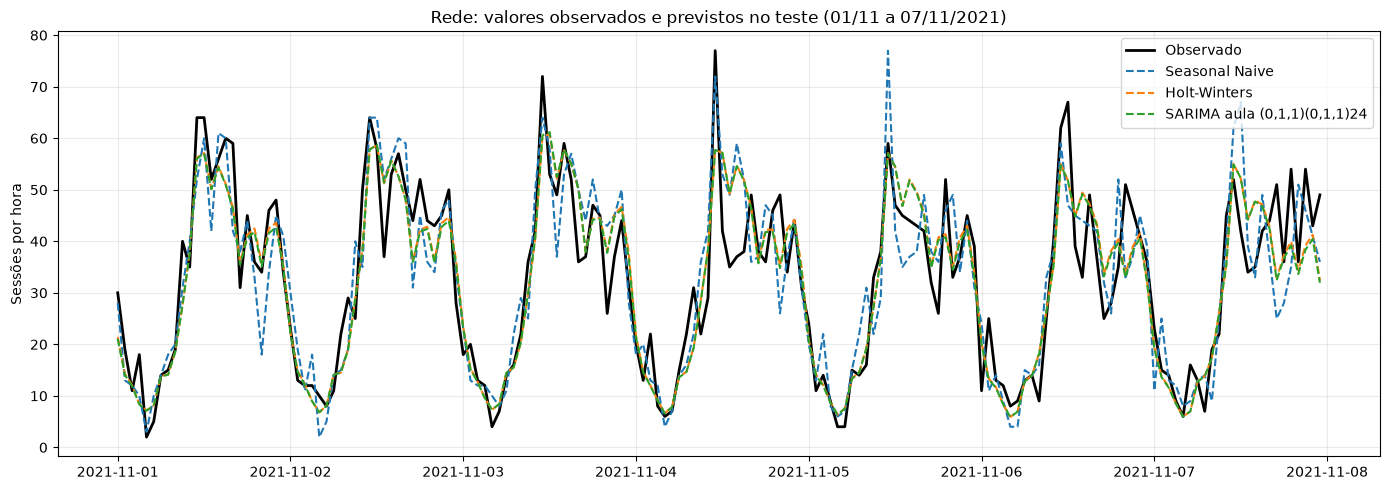

In [22]:
semana = slice('2021-11-01', '2021-11-07')

plt.figure(figsize=(14, 5))
plt.plot(test['Rede'].loc[semana], color='black', linewidth=2, label='Observado')
plt.plot(sn_teste['Rede'].loc[semana], linestyle='--', label='Seasonal Naive')
plt.plot(previsoes_teste[('Rede', 'Holt-Winters')].loc[semana], linestyle='--', label='Holt-Winters')
plt.plot(previsoes_teste[('Rede', nome_sarima)].loc[semana], linestyle='--', label=nome_sarima)
plt.title('Rede: valores observados e previstos no teste (01/11 a 07/11/2021)')
plt.ylabel('Sessões por hora')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Hipóteses e validação:**

- **H13 - O Holt-Winters continua a ganhar ao Seasonal Naive no teste: Confirmada.**
  O MASE desce face ao Seasonal Naive em todas as séries: rede 1,114 → **0,853** (−23%), Nanhu 1,023 → **0,837** (−18%), Tongxiang 1,090 → **0,804** (−26%) e Xiuzhou 1,283 → **0,946** (−26%).
  A redução é semelhante à da validação (22% a 26%, secção 6.2), por isso o desempenho é **estável** e a escolha feita na validação confirma-se em dados novos. Nanhu é a série com a menor melhoria, o que é compatível com as interrupções de locais neste distrito durante o teste.
  O SARIMA(0,1,1)(0,1,1)₂₄ fica praticamente igual ao Holt-Winters (diferença máxima de 0,004 de MASE).

**Gráfico (rede, 01/11 a 07/11/2021):**
- O Holt-Winters e o SARIMA dão previsões quase sobrepostas e mais **suaves** do que o Seasonal Naive. Acompanham bem o padrão diário (mínimo de madrugada, subida de manhã e procura alta à tarde).
- O Seasonal Naive copia o dia anterior, incluindo picos e quedas que não se repetem (por exemplo, o pico de 04/11 é repetido a 05/11).
- Os modelos **subestimam os picos mais altos** (por exemplo, cerca de 77 sessões a 04/11). Estes picos não se repetem de forma regular e os modelos preveem um comportamento médio.

## 8. Síntese

| Modelo | MASE validação (Rede / Nanhu / Tongxiang / Xiuzhou) | Tempo de ajuste por série | Observação |
|---|---|---|---|
| Seasonal Naive | 1,187 / 0,979 / 1,159 / 1,342 | — | Baseline de referência |
| **Holt-Winters** (ETS(A,N,A) sobre log(1 + y)) | **0,890 / 0,765 / 0,852 / 1,010** | < 1 s | **Modelo escolhido** |
| SARIMA da aula (0,1,1)(0,1,1)₂₄ | 0,894 / 0,765 / 0,853 / 1,012 | 15 a 21 s | Praticamente igual ao Holt-Winters |
| SARIMA(1,0,1)(0,1,1)₂₄ | 0,893 / 0,775 / 0,855 / 1,012 | 30 a 44 s | AR ≈ 1 aproxima uma diferença regular |
| SARIMAX(1,0,1)(0,1,1)₂₄ + dia da semana | 0,898 / 0,789 / 0,857 / 1,015 | 266 a 350 s | Mais lento e sem ganho |

**Teste (Holt-Winters):** MASE de 0,853 / 0,837 / 0,804 / 0,946, contra 1,114 / 1,023 / 1,090 / 1,283 do Seasonal Naive.

**Principais conclusões:**
- **Comparação com as baselines:** todos os modelos estatísticos ganham ao Seasonal Naive nas 4 séries, com reduções de cerca de 18% a 26% do MASE na validação e no teste.
- **Entre os modelos:** as diferenças são muito pequenas. O Holt-Winters foi escolhido por ter o menor erro e ser, de longe, o mais rápido e simples.
- **Horizontes:** o erro não cresce com o horizonte. Segue o padrão diário da procura: é baixo de madrugada e alto à tarde (secção 6.3).
- **Estabilidade:** os modelos ganham ao Seasonal Naive em todos os meses da validação e mantêm a mesma vantagem no teste.
- **Níveis de agregação:** o comportamento é o mesmo na rede e nos distritos. Em termos relativos, Xiuzhou é a série mais difícil e Nanhu é a mais afetada pelas interrupções de locais.
- **Diagnóstico:** os resíduos têm autocorrelações muito pequenas, mas não são ruído branco (Ljung-Box), e têm uma cauda esquerda longa por causa das horas com 0 ou 1 sessões na escala log.

**Limitações:**
- **Sazonalidade múltipla:** o Holt-Winters e o SARIMA representam apenas **uma** sazonalidade (*m* = 24). A sazonalidade semanal foi incluída no SARIMAX através do dia da semana, mas não melhorou as previsões, porque é fraca (Task 1, H13). Um SARIMA com *m* = 168 seria muito pesado com dados horários.
- Os modelos não incluem **feriados** (por exemplo, a véspera de Ano Novo aparece como uma subida do nível) e **subestimam os picos** irregulares.
- As previsões são **suaves**: representam o comportamento médio de cada hora e não as variações bruscas.
- Os modelos são univariados. As variáveis meteorológicas foram excluídas, porque os seus valores futuros não estão disponíveis na origem (Task 1, secção 3.3).

**Utilidade operacional:** o Holt-Winters ajusta-se em menos de 1 segundo e cada previsão diária é imediata, por isso pode ser usado facilmente todos os dias às 23:00 para as 4 séries. Dá uma estimativa fiável do perfil horário do dia seguinte, mas não deve ser usado sozinho para antecipar picos excecionais.